In [41]:
import numpy as np
import cv2 as cv
from matplotlib import pyplot as plt
from skimage.feature import peak_local_max
from skimage.metrics import structural_similarity as ssim, mean_squared_error

# 1. Реализуйте высокочастотную фильтрацию на основе ядра Гаусса

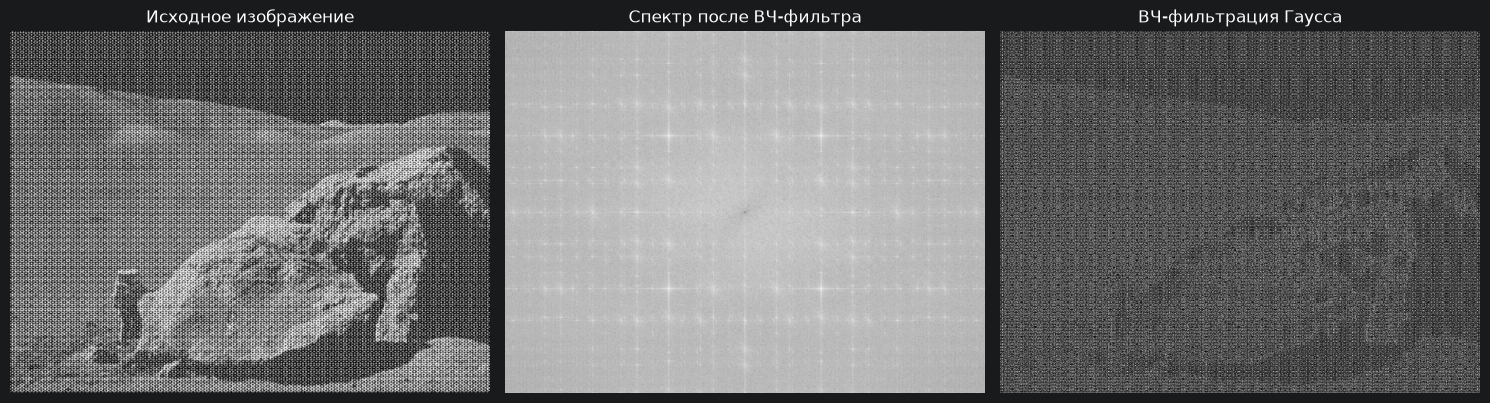

In [42]:
img = cv.imread('periodic_noise.jpg', cv.IMREAD_GRAYSCALE)

rows, cols = img.shape
crow, ccol = rows // 2, cols // 2

dft = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_shift = np.fft.fftshift(dft)
magnitude_spectrum = 20 * np.log(cv.magnitude(dft_shift[:, :, 0], dft_shift[:, :, 1]) + 1e-5)

sigma = 30
x = np.arange(0, cols, 1)
y = np.arange(0, rows, 1)
X, Y = np.meshgrid(x, y)
gaussian_mask = np.exp(-((X - ccol)**2 + (Y - crow)**2) / (2.0 * sigma**2))
high_pass_mask = 1.0 - gaussian_mask

dft_shift_high_pass = dft_shift * high_pass_mask[:, :, np.newaxis]
f_ishift_high_pass = np.fft.ifftshift(dft_shift_high_pass)
img_back_high_pass = cv.idft(f_ishift_high_pass)
img_back_high_pass = cv.magnitude(img_back_high_pass[:, :, 0], img_back_high_pass[:, :, 1])

img_back_high_pass = img_back_high_pass / (rows * cols)
img_back_high_pass = np.clip(img_back_high_pass, 0, 255).astype(np.uint8)

hp_spectrum = 20 * np.log(cv.magnitude(dft_shift_high_pass[:, :, 0], dft_shift_high_pass[:, :, 1]) + 1e-5)

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(hp_spectrum, cmap='gray')
plt.title('Спектр после ВЧ-фильтра')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(img_back_high_pass, cmap='gray')
plt.title(f'ВЧ-фильтрация Гаусса')
plt.axis('off')
plt.tight_layout()
plt.show()

  MSE:  160.1647
  SSIM: 0.6483
  Максимальная абсолютная разница: 76


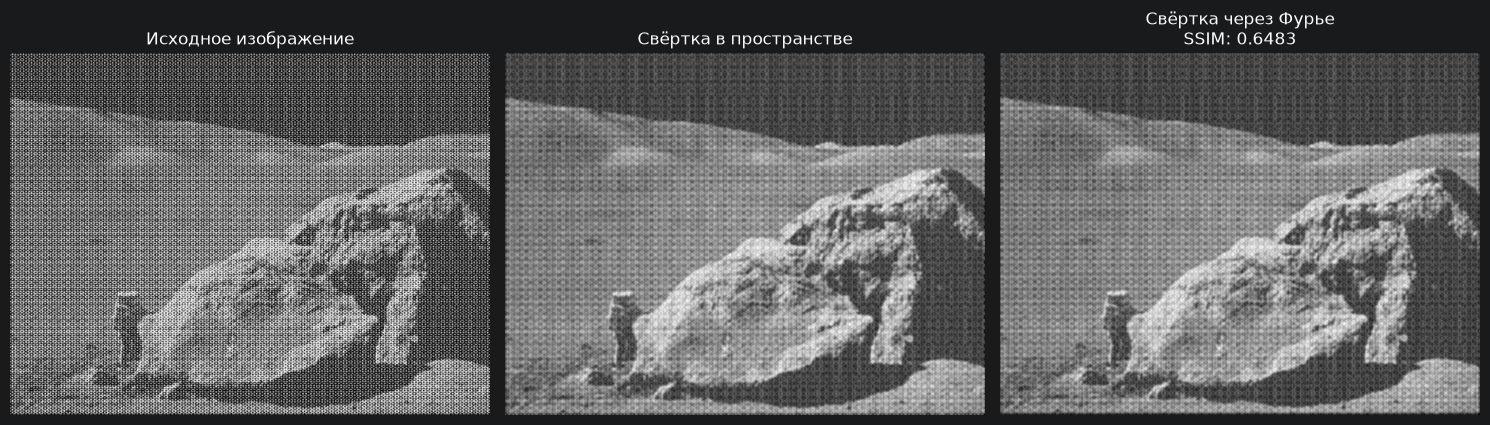

In [43]:
kernel_size = 5
kernel = cv.getGaussianKernel(kernel_size, sigma=1.5)
kernel = kernel * kernel.T

spatial_conv = cv.filter2D(img, -1, kernel)

kernel_padded = np.zeros((rows, cols), dtype=np.float32)
k_h, k_w = kernel.shape
kernel_padded[:k_h, :k_w] = kernel
kernel_padded = np.roll(kernel_padded, -k_h // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -k_w // 2, axis=1)

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

re = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
im = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]
dft_conv = np.stack([re, im], axis=-1)

fourier_conv = cv.idft(dft_conv)
fourier_conv = fourier_conv[:, :, 0] / (rows * cols)
fourier_conv = np.clip(fourier_conv, 0, 255).astype(np.uint8)

mse_val = mean_squared_error(spatial_conv, fourier_conv)
ssim_val = ssim(spatial_conv, fourier_conv, data_range=255)
diff = cv.absdiff(spatial_conv, fourier_conv)

print(f"  MSE:  {mse_val:.4f}")
print(f"  SSIM: {ssim_val:.4f}")
print(f"  Максимальная абсолютная разница: {np.max(diff)}")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(spatial_conv, cmap='gray')
plt.title('Свёртка в пространстве')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(fourier_conv, cmap='gray')
plt.title(f'Свёртка через Фурье\nSSIM: {ssim_val:.4f}')
plt.axis('off')
plt.tight_layout()
plt.show()

# 2. Реализуйте удаление периодического шума с помощью преобразования Фурье

  MSE:  160.1647
  SSIM: 0.6483
  Максимальная абсолютная разница: 76


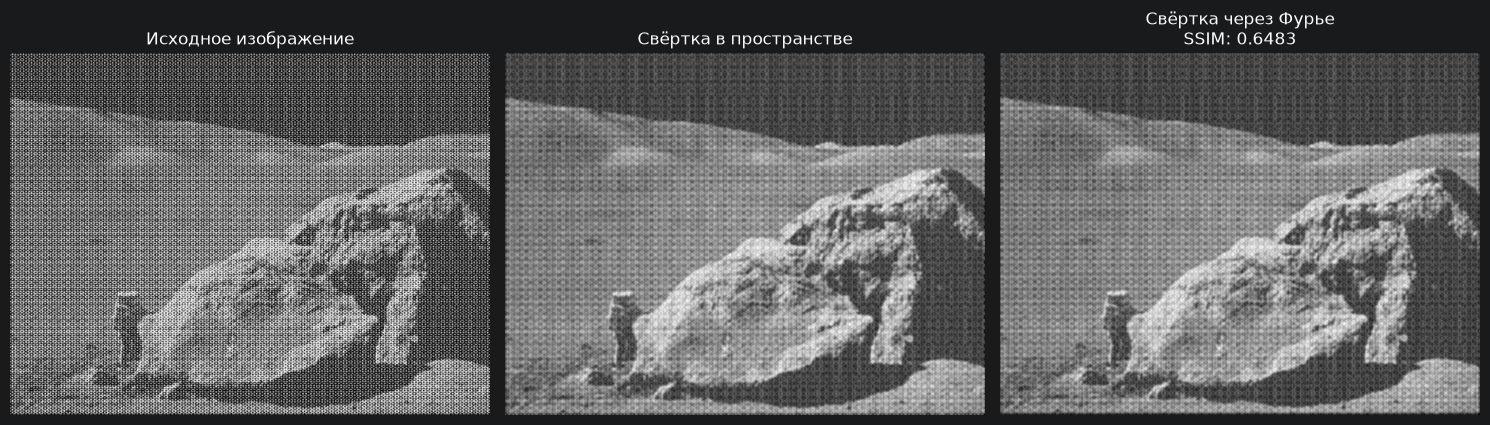

In [44]:
kernel_size = 5
kernel = cv.getGaussianKernel(kernel_size, sigma=1.5)
kernel = kernel * kernel.T

spatial_conv = cv.filter2D(img, -1, kernel)

kernel_padded = np.zeros((rows, cols), dtype=np.float32)
k_h, k_w = kernel.shape
kernel_padded[:k_h, :k_w] = kernel
kernel_padded = np.roll(kernel_padded, -k_h // 2, axis=0)
kernel_padded = np.roll(kernel_padded, -k_w // 2, axis=1)

dft_img = cv.dft(np.float32(img), flags=cv.DFT_COMPLEX_OUTPUT)
dft_kernel = cv.dft(kernel_padded, flags=cv.DFT_COMPLEX_OUTPUT)

re = dft_img[:, :, 0] * dft_kernel[:, :, 0] - dft_img[:, :, 1] * dft_kernel[:, :, 1]
im = dft_img[:, :, 0] * dft_kernel[:, :, 1] + dft_img[:, :, 1] * dft_kernel[:, :, 0]
dft_conv = np.stack([re, im], axis=-1)

fourier_conv = cv.idft(dft_conv)
fourier_conv = fourier_conv[:, :, 0] / (rows * cols)
fourier_conv = np.clip(fourier_conv, 0, 255).astype(np.uint8)

mse_val = mean_squared_error(spatial_conv, fourier_conv)
ssim_val = ssim(spatial_conv, fourier_conv, data_range=255)
diff = cv.absdiff(spatial_conv, fourier_conv)

print(f"  MSE:  {mse_val:.4f}")
print(f"  SSIM: {ssim_val:.4f}")
print(f"  Максимальная абсолютная разница: {np.max(diff)}")

plt.figure(figsize=(15, 5))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Исходное изображение')
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(spatial_conv, cmap='gray')
plt.title('Свёртка в пространстве')
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(fourier_conv, cmap='gray')
plt.title(f'Свёртка через Фурье\nSSIM: {ssim_val:.4f}')
plt.axis('off')
plt.tight_layout()
plt.show()

# 3 Реализуйте удаление периодического шума

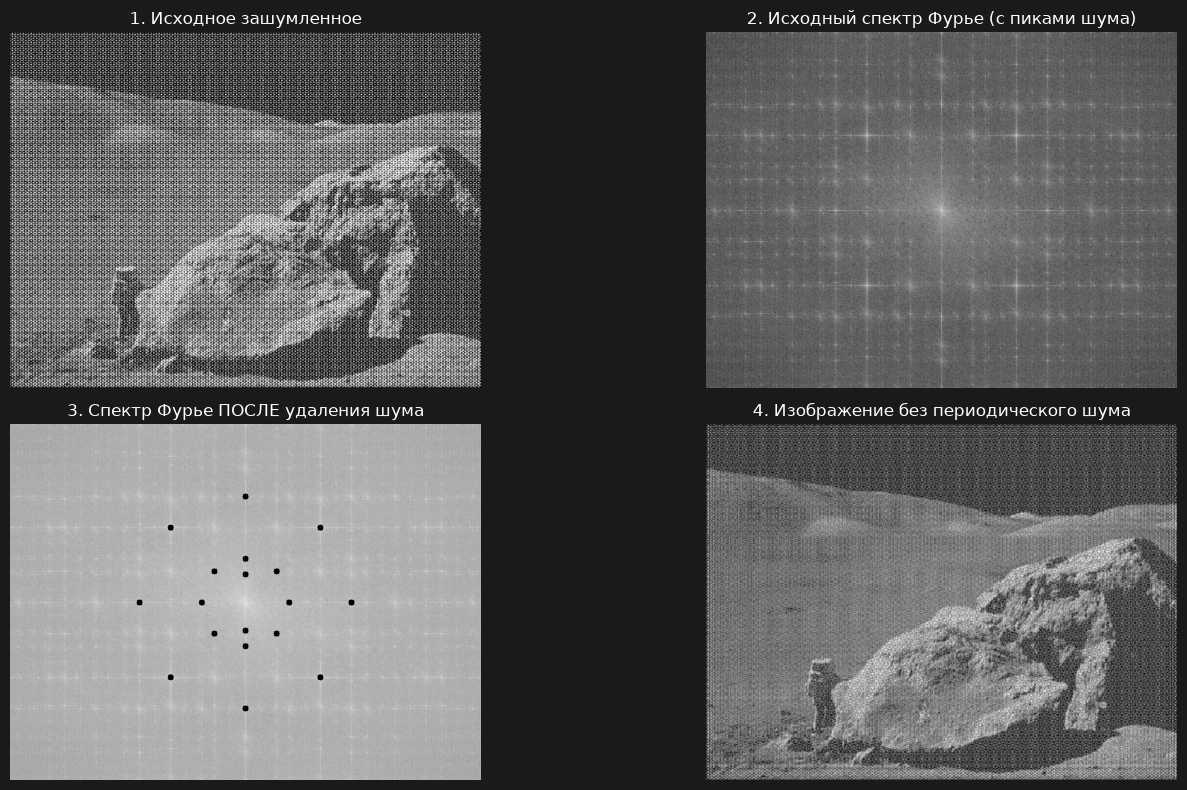

In [45]:
min_distance = 15
threshold_abs = 285
noise_coords = peak_local_max(magnitude_spectrum, min_distance=min_distance, threshold_abs=threshold_abs)

mask_noise = np.ones_like(dft_shift)
radius = 5

for coord in noise_coords:
    if np.hypot(coord[0] - crow, coord[1] - ccol) > 15:
        cv.circle(mask_noise, (coord[1], coord[0]), radius, (0, 0), -1)

dft_shift_noise_removed = dft_shift * mask_noise

filtered_spectrum = 20 * np.log(cv.magnitude(dft_shift_noise_removed[:, :, 0],
                                            dft_shift_noise_removed[:, :, 1]) + 1e-5)

f_ishift_noise_removed = np.fft.ifftshift(dft_shift_noise_removed)
img_back_noise_removed = cv.idft(f_ishift_noise_removed)
img_back_noise_removed = cv.magnitude(img_back_noise_removed[:, :, 0], img_back_noise_removed[:, :, 1])
img_back_noise_removed = img_back_noise_removed / (rows * cols)
img_back_noise_removed = np.clip(img_back_noise_removed, 0, 255).astype(np.uint8)

plt.figure(figsize=(16, 8))

plt.subplot(2, 2, 1)
plt.imshow(img, cmap='gray')
plt.title('1. Исходное зашумленное')
plt.axis('off')

plt.subplot(2, 2, 2)
plt.imshow(magnitude_spectrum, cmap='gray')
plt.title('2. Исходный спектр Фурье (с пиками шума)')
plt.axis('off')

plt.subplot(2, 2, 3)
plt.imshow(filtered_spectrum, cmap='gray')
plt.title('3. Спектр Фурье ПОСЛЕ удаления шума')
plt.axis('off')

plt.subplot(2, 2, 4)
plt.imshow(img_back_noise_removed, cmap='gray')
plt.title('4. Изображение без периодического шума')
plt.axis('off')

plt.tight_layout()
plt.show()